# SPARCS 2024 inpatient discharges: data understanding, cleaning and EDA

**Goal:** predict the length of stay (`los`) of a patient once admitted, from information known at admission.

**Data:** [SPARCS Hospital Inpatient Discharges (De-identified), 2024](https://health.data.ny.gov/d/sf4k-39ay), New York State Department of Health.

**Contents**
1. Setup and load
2. Data understanding
3. Data cleaning
4. EDA charts

## 1. Setup and load

In [1]:
import os
import textwrap
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from dotenv import load_dotenv
from scipy.stats import chi2_contingency

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.float_format", "{:,.2f}".format)

The data is requested from the Socrata (SODA) API in pages of 50,000 rows, ordered by the built-in `:id` so pages do not overlap. The result is cached as parquet; delete the file to force a fresh download. An `APP_TOKEN` in `.env` is optional and only avoids throttling.

In [2]:
BASE_URL = "https://health.data.ny.gov/resource/sf4k-39ay.json"
PAGE_SIZE = 50000
CACHE_PATH = Path("../data/raw/sparcs_2024_raw.parquet")
CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
load_dotenv()
app_token = os.environ.get("APP_TOKEN")

In [3]:
HEADERS = {"X-App-Token": app_token} if app_token else {}

def fetch_page(offset):
    params = {"$limit": PAGE_SIZE, "$offset": offset, "$order": ":id"}
    resp = requests.get(BASE_URL, params=params, timeout=120, headers=HEADERS)
    resp.raise_for_status()
    return resp.json()


if CACHE_PATH.exists():
    df_raw = pd.read_parquet(CACHE_PATH)
    print("loaded from cache")
else:
    rows, offset = [], 0
    while True:
        page = fetch_page(offset)
        if not page:                       # an empty page means we are past the last row
            break
        rows.extend(page)
        offset += PAGE_SIZE
        print(f"fetched {len(rows):,} rows")
    df_raw = pd.DataFrame(rows)
    df_raw.to_parquet(CACHE_PATH)
    print("downloaded and saved to cache")

print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")

loaded from cache
Rows: 2,196,737 | Columns: 33


In [4]:
# Sanity check: does the row count match the API?
try:
    resp = requests.get(BASE_URL, params={"$select": "count(*)"}, headers=HEADERS, timeout=30)
    resp.raise_for_status()
    total_rows = int(resp.json()[0]["count"])
    print("row count matches the API" if len(df_raw) == total_rows
          else f"MISMATCH: API has {total_rows:,} rows, DataFrame has {len(df_raw):,}")
except requests.RequestException as err:
    print("API not reachable, skipping the check:", type(err).__name__)

row count matches the API


## 2. Data understanding

### 2.1 First look

In [5]:
summary = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_unique": df_raw.nunique(),
    "n_missing": df_raw.isna().sum(),
    "pct_missing": (df_raw.isna().mean() * 100).round(2),
    "example_values": df_raw.apply(lambda s: s.dropna().unique()[:4].tolist()),
})
summary.sort_values("n_unique")

,dtype,n_unique,n_missing,pct_missing,example_values
discharge_year,str,1,0,0.00,[2024]
emergency_department_indicator,str,2,0,0.00,"[Y, N]"
apr_medical_surgical,str,3,0,0.00,"[Medical, Surgical, Not Applicable]"
gender,str,3,0,0.00,"[F, M, U]"
race,str,4,0,0.00,"[White, Other Race, Black/African American, Mu..."
ethnicity,str,4,0,0.00,"[Not Span/Hispanic, Spanish/Hispanic, Unknown,..."
age_group,str,5,0,0.00,"[0-17, 70 or Older, 18-29, 30-49]"
apr_risk_of_mortality,str,5,0,0.00,"[Minor, Moderate, Major, Extreme]"
apr_severity_of_illness,str,5,0,0.00,"[Moderate, Minor, Major, Extreme]"
apr_severity_of_illness_code,str,5,0,0.00,"[2, 1, 3, 4]"


**Observations**
- All columns are read as text. Numeric columns (`length_of_stay`, `total_charges`, `total_costs`, `birth_weight`) need converting before use.
- `discharge_year` has one value (2024).
- Five code and description pairs have the same number of unique values: severity, MDC, DRG, CCSR diagnosis, CCSR procedure.
- `permanent_facility_id`, `operating_certificate_number`, `hospital_county` and `health_service_area` have the same number of missing values (5,295). The data dictionary says these are blanked for records with enhanced de-identification.
- `payment_typology_2` is 54.83% missing and `payment_typology_3` is 89.07% missing. `payment_typology_1` is 0.01% missing.
- `birth_weight` is 90.54% missing. `ccsr_procedure_code` is 29.31% missing. `zip_code` is 1.91% missing.
- 205 facility IDs against 203 facility names, and 158 operating certificates against 205 facility IDs.
- `length_of_stay` has 120 unique values and no missing values.

Each of these is checked in section 3.

### 2.2 Column groups

| Group | Columns |
|---|---|
| Facility and geography | `permanent_facility_id`, `facility_name`, `operating_certificate_number`, `hospital_county`, `health_service_area`, `zip_code` |
| Patient | `age_group`, `gender`, `race`, `ethnicity` |
| Admission | `type_of_admission`, `emergency_department_indicator`, `discharge_year` |
| Diagnosis and procedure (CCSR) | `ccsr_diagnosis_code`, `ccsr_diagnosis_description`, `ccsr_procedure_code`, `ccsr_procedure_description` |
| APR-DRG grouper output | `apr_drg_code`, `apr_drg_description`, `apr_mdc_code`, `apr_mdc_description`, `apr_severity_of_illness_code`, `apr_severity_of_illness`, `apr_risk_of_mortality`, `apr_medical_surgical` |
| Payer | `payment_typology_1`, `payment_typology_2`, `payment_typology_3` |
| Newborn | `birth_weight` |
| Outcome and cost | `length_of_stay` (target), `patient_disposition`, `total_charges`, `total_costs` |

### 2.3 Target variable

In [6]:
los_raw = df_raw["length_of_stay"]
non_numeric = los_raw[pd.to_numeric(los_raw, errors="coerce").isna()]
print("non-numeric tokens:\n", non_numeric.value_counts(), "\n")
print("rows with a plain '120':", (los_raw == "120").sum())

non-numeric tokens:
 length_of_stay
120+    2404
Name: count, dtype: int64 

rows with a plain '120': 0


In [7]:
# df_eda = df_raw plus the numeric target. "120+" becomes 120.
df_eda = df_raw.assign(
    los=pd.to_numeric(df_raw["length_of_stay"].str.replace("+", "", regex=False), errors="raise")
)
los = df_eda["los"]

print(los.describe(percentiles=[.05, .25, .5, .75, .9, .95, .99]).round(2), "\n")
print("mean:", round(los.mean(), 2), "| median:", los.median(), "| skew:", round(los.skew(), 2), "\n")
for t in [7, 14, 30, 60, 100]:
    n = (los > t).sum()
    print(f"LOS > {t:3d} days: {n:>8,}  ({n / len(los) * 100:.2f}%)")

count   2,196,737.00
mean            5.81
std             8.83
min             1.00
5%              1.00
25%             2.00
50%             3.00
75%             6.00
90%            12.00
95%            19.00
99%            42.00
max           120.00
Name: los, dtype: float64 

mean: 5.81 | median: 3.0 | skew: 6.14 

LOS >   7 days:  440,946  (20.07%)
LOS >  14 days:  168,444  (7.67%)
LOS >  30 days:   41,013  (1.87%)
LOS >  60 days:   10,391  (0.47%)
LOS > 100 days:    3,510  (0.16%)


**Observations**
- `length_of_stay` has one non-numeric token, `"120+"`, on 2,404 rows. There is no plain `"120"`, so the target is right-censored at 120.
- `los` runs from 1 to 120 days with a median of 3 and a mean of 5.81. There are no zero-day stays.
- The distribution is strongly right-skewed: the mean is well above the median and the tail runs to 120 days.

**Decision**
- `"120+"` is converted to 120 in the numeric target `los`. These rows are identifiable as `los == 120`, so no separate flag is kept.
- A log transform of the target is a candidate for modelling.

## 3. Data cleaning

### 3.1 Constant column

In [8]:
print(df_raw["discharge_year"].unique())

<ArrowStringArray>
['2024']
Length: 1, dtype: str


`discharge_year` has the single value 2024 and cannot explain length of stay.

**Decision:** drop `discharge_year`.

### 3.2 Leakage: columns that describe the completed stay

The model predicts the stay of a patient who has just been admitted, so a column that describes the finished stay cannot be a feature.

- `patient_disposition` is where the patient went after leaving (home, transferred, expired, and so on). It is a discharge outcome.
- `total_charges` and `total_costs` are the amount billed and the cost of the whole stay. Both grow with every extra day, so a model using them would read the answer off.

**Decision:** drop `patient_disposition`, `total_charges`, `total_costs`.

### 3.3 Code and description pairs

In [9]:
pairs = [("apr_severity_of_illness_code", "apr_severity_of_illness"),
         ("apr_mdc_code", "apr_mdc_description"),
         ("apr_drg_code", "apr_drg_description"),
         ("ccsr_diagnosis_code", "ccsr_diagnosis_description"),
         ("ccsr_procedure_code", "ccsr_procedure_description")]

for code_col, desc_col in pairs:
    desc_per_code = df_raw.groupby(code_col)[desc_col].nunique().max()
    code_per_desc = df_raw.groupby(desc_col)[code_col].nunique().max()
    print(f"{code_col:30s} descriptions per code: {desc_per_code} | codes per description: {code_per_desc}")

apr_severity_of_illness_code   descriptions per code: 1 | codes per description: 1
apr_mdc_code                   descriptions per code: 1 | codes per description: 1
apr_drg_code                   descriptions per code: 1 | codes per description: 1
ccsr_diagnosis_code            descriptions per code: 1 | codes per description: 1
ccsr_procedure_code            descriptions per code: 1 | codes per description: 1


Each code maps to exactly one description and the other way round, so the description carries no extra information.

**Decision:** keep the code columns, drop `apr_severity_of_illness`, `apr_mdc_description`, `apr_drg_description`, `ccsr_diagnosis_description`, `ccsr_procedure_description`. The descriptions are still read from `df_raw` to label charts.

### 3.4 Redacted facility records (rows)

In [10]:
fac = ["permanent_facility_id", "operating_certificate_number", "hospital_county", "health_service_area"]
print("rows with all 4 missing:", df_eda[fac].isna().all(axis=1).sum())
print("rows with any of the 4 missing:", df_eda[fac].isna().any(axis=1).sum())

red = df_eda["permanent_facility_id"].isna()
print("redacted rows:", red.sum(), f"({red.mean() * 100:.2f}%)")
print(df_eda.loc[red, "facility_name"].value_counts().head(3))

rows with all 4 missing: 5295
rows with any of the 4 missing: 5295
redacted rows: 5295 (0.24%)
facility_name
Redacted for Confidentiality    5295
Name: count, dtype: int64


**Observations**
- All four facility fields are missing on the same 5,295 rows (0.24% of the data), and `facility_name` is "Redacted for Confidentiality" on every one of them.
- SPARCS states that discharges identified as abortion have these fields redacted. 
- Facility fields are identifiers, so imputing them would assign real patients to a hospital they were not treated in.

**Decision:** drop the 5,295 (0.24% data) redacted rows (`df_nonredacted`).

In [11]:
df_nonredacted = df_eda[df_eda["permanent_facility_id"].notna()].copy()
print(f"rows before: {len(df_eda):,} | after: {len(df_nonredacted):,}")

rows before: 2,196,737 | after: 2,191,442


### 3.5 Facility and geography hierarchy

In [12]:
grp = df_nonredacted.groupby
print("max ids per facility name:", grp("facility_name")["permanent_facility_id"].nunique().max())
print("max names per facility id:", grp("permanent_facility_id")["facility_name"].nunique().max())
print("max certificates per facility id:", grp("permanent_facility_id")["operating_certificate_number"].nunique().max())

ids_per_cert = grp("operating_certificate_number")["permanent_facility_id"].nunique()
print("max ids per certificate:", ids_per_cert.max())
print("certificates covering more than one id:", (ids_per_cert > 1).sum(), "of", len(ids_per_cert))

ids_per_name = df_nonredacted.groupby("facility_name")["permanent_facility_id"].nunique()   # distinct ids per name
shared = ids_per_name[ids_per_name > 1]                                                    # names with more than one id
print(len(shared), "names are shared by more than one id")
print(shared)

max ids per facility name: 2
max names per facility id: 1
max certificates per facility id: 1
max ids per certificate: 8
certificates covering more than one id: 31 of 158
3 names are shared by more than one id
facility_name
BRONXCARE HOSPITAL CENTER                                               2
THE UNIVERSITY OF VERMONT HEALTH NETWORK - ALICE HYDE MEDICAL CENTER    2
WYOMING COUNTY COMMUNITY HOSPITAL                                       2
Name: permanent_facility_id, dtype: int64


**Observations**
- Each facility ID has exactly one name, but three names are shared by two IDs. The name is determined by the ID, not the other way round.
- Each facility ID sits under exactly one operating certificate. 31 of 158 certificates cover more than one facility (up to 8). County and health service area are also determined by the facility.

**Decision:**
- Drop `facility_name`, since it is fully determined by `permanent_facility_id` and ambiguous.
- `operating_certificate_number`, `hospital_county` and `health_service_area` are coarser groupings of the facility.

### 3.6 Zip code

In [13]:
z = df_nonredacted["zip_code"]
print("missing:", z.isna().sum(), f"({z.isna().mean() * 100:.2f}%)")
print("OOS:", z.eq("OOS").sum())
z.value_counts().head(5)

missing: 36677 (1.67%)
OOS: 65078


zip_code
112    266231
104    207886
117    188654
100    152265
113    111758
Name: count, dtype: int64

SPARCS keeps only the first three digits and blanks the zip code for small populations (under 20,000), small cells (under 10) or abortion records. `OOS` means out of state.

**Decision:** `OOS` is a valid value and is kept. Missing values are deliberate suppression, so they are labelled `Suppressed` (a separate level from `OOS`) and not imputed.

### 3.7 Payment typology

In [14]:
p1, p2, p3 = (df_nonredacted[f"payment_typology_{i}"] for i in (1, 2, 3))

vc = p1.value_counts(dropna=False)
print(pd.DataFrame({"rows": vc, "pct": (vc / len(p1) * 100).round(2)}), "\n")

print("typology 2 missing:", f"{p2.isna().mean() * 100:.2f}%", "| typology 3 missing:", f"{p3.isna().mean() * 100:.2f}%")
print("typology 1 missing but typology 2 present:", (p1.isna() & p2.notna()).sum())
print("typology 2 missing but typology 3 present:", (p2.isna() & p3.notna()).sum())

                             rows   pct
payment_typology_1                     
Medicare                   928688 42.38
Medicaid                   632965 28.88
Private Health Insurance   316720 14.45
Blue Cross/Blue Shield     203582  9.29
Self-Pay                    34611  1.58
Managed Care, Unspecified   30237  1.38
Miscellaneous/Other         21724  0.99
Federal/State/Local/VA      21068  0.96
Department of Corrections    1620  0.07
NaN                           227  0.01 

typology 2 missing: 54.79% | typology 3 missing: 89.06%
typology 1 missing but typology 2 present: 80
typology 2 missing but typology 3 present: 6


**Observations**
- `payment_typology_1` has 9 levels, led by Medicare (42.38%), Medicaid (28.88%) and Private Health Insurance (14.45%). 227 rows (0.01%) are missing, and 80 of them have a second payer, so the first payer was left blank while later slots were filled.
- `payment_typology_2` is missing on 54.79% of rows and `payment_typology_3` on 89.06%. This means no additional payer, not a data-quality problem.

**Decision:** no imputation. Missing values are labelled `Not recorded` (typology 1), `No second payer` (typology 2) and `No third payer` (typology 3). Insurance is normally collected at registration, so the payer is treated as known at admission.

### 3.8 Type of admission, and the newborn cohort

In [15]:
t = df_nonredacted["type_of_admission"]
vc = t.value_counts(dropna=False)
print(pd.DataFrame({"rows": vc, "pct": (vc / len(t) * 100).round(2)}), "\n")

# Share of each admission type that passes through the emergency department (rows sum to 100)
print((pd.crosstab(t, df_nonredacted["emergency_department_indicator"], normalize="index") * 100).round(2), "\n")

# Birth weight by admission type (rows sum to 100)
has_weight = df_nonredacted["birth_weight"].notna().rename("has_birth_weight")
print((pd.crosstab(t, has_weight, normalize="index") * 100).round(2))

                      rows   pct
type_of_admission               
Emergency          1456451 66.46
Elective            355154 16.21
Newborn             197959  9.03
Urgent              168194  7.68
Trauma               10038  0.46
Not Available         3646  0.17 

emergency_department_indicator     N     Y
type_of_admission                         
Elective                       97.63  2.37
Emergency                       8.84 91.16
Newborn                        99.91  0.09
Not Available                  89.11 10.89
Trauma                          6.48 93.52
Urgent                         83.67 16.33 

has_birth_weight   False  True 
type_of_admission              
Elective           99.75   0.25
Emergency          99.57   0.43
Newborn             0.03  99.97
Not Available      99.15   0.85
Trauma             99.82   0.18
Urgent             98.56   1.44


**Observations**
- Six admission types: Emergency (66.46%), Elective (16.21%), Newborn (9.03%), Urgent (7.68%), Trauma (0.46%) and Not Available (0.17%).
- Admission type and the emergency department indicator overlap but are not copies: 93.52% of Trauma and 91.16% of Emergency admissions pass through the ED, against 16.33% of Urgent and 2.37% of Elective.
- `birth_weight` is recorded for 99.97% of Newborn admissions. Outside the newborn group the column is almost empty.

**Decision:**
- Keep both `type_of_admission` and `emergency_department_indicator`.
- Newborn admissions are a birth in the hospital, a different process from the one being predicted. They are set aside as `df_newborn` and excluded from the main cohort `df_main`. `birth_weight` is dropped from the main model.

In [16]:
is_newborn = df_nonredacted["type_of_admission"].eq("Newborn")
df_main = df_nonredacted[~is_newborn].copy()
df_newborn = df_nonredacted[is_newborn].copy()
print(f"main cohort: {len(df_main):,} | newborn cohort: {len(df_newborn):,}")

main cohort: 1,993,483 | newborn cohort: 197,959


### 3.9 Gender, race and ethnicity

In [17]:
for c in ["gender", "race", "ethnicity"]:
    vc = df_main[c].value_counts(dropna=False)
    print(f"=== {c} ({df_main[c].nunique()} levels) ===")
    print(pd.DataFrame({"rows": vc, "pct": (vc / len(df_main) * 100).round(2)}))

=== gender (3 levels) ===
           rows   pct
gender               
F       1094776 54.92
M        898586 45.08
U           121  0.01
=== race (4 levels) ===
                           rows   pct
race                                 
White                   1057481 53.05
Other Race               536960 26.94
Black/African American   370947 18.61
Multi-racial              28095  1.41
=== ethnicity (4 levels) ===
                      rows   pct
ethnicity                       
Not Span/Hispanic  1423788 71.42
Spanish/Hispanic    326479 16.38
Unknown             240857 12.08
Multi-ethnic          2359  0.12


No missing values. Unknown values appear as explicit levels: `gender` `U` (121 rows, 0.01%) and `ethnicity` `Unknown` (240,857 rows, 12.08%).

**Decision:** keep the unknown levels as they are.

### 3.10 Ungroupable records

In [18]:
sev0 = df_main["apr_severity_of_illness_code"].eq("0")      
rom_undetermined = df_main["apr_risk_of_mortality"].eq("Undetermined")
med_surg_na = df_main["apr_medical_surgical"].eq("Not Applicable")

print("severity 0:", sev0.sum(), "| mortality Undetermined:", rom_undetermined.sum(),"| medical/surgical Not Applicable:", med_surg_na.sum())
print("all three together:", (sev0 & rom_undetermined & med_surg_na).sum())
print("any of the three:", (sev0 | rom_undetermined | med_surg_na).sum())

severity 0: 381 | mortality Undetermined: 381 | medical/surgical Not Applicable: 381
all three together: 381
any of the three: 381


**Observations**
- The same 381 rows (0.02% of the main cohort) have severity `0`, risk of mortality `Undetermined` and medical/surgical `Not Applicable`.
- Severity and risk of mortality are ordered scales, and these values are not a level on either.

**Decision:** drop the 381 rows. They are filtered before the grouper columns are dropped.

### 3.11 Missing procedure code

In [19]:
proc_missing = df_main["ccsr_procedure_code"].isna().rename("procedure_missing")
print(f"missing: {proc_missing.sum():,} ({proc_missing.mean() * 100:.2f}%)\n")
print((pd.crosstab(df_main["apr_medical_surgical"], proc_missing, normalize="columns") * 100).round(2))

missing: 581,407 (29.17%)

procedure_missing     False  True 
apr_medical_surgical              
Medical               64.07  99.98
Not Applicable         0.02   0.02
Surgical              35.92   0.00


The missing values are almost all on medical stays and none are on surgical stays, so a blank means no procedure was recorded for the stay and not lost data.

**Decision:** label them `No procedure recorded` and keep them as their own level.

### 3.12 Discharge-time grouper columns, and building `df_clean`

The 3M APR-DRG Methodology Overview (HCUP, version 41.0) states that the base APR DRG, severity of illness subclass and risk of mortality subclass "represent the patient's condition at the time of discharge and include the impact of conditions that developed during the hospital stay" (p. 53).

**Decision:** drop `apr_severity_of_illness_code`, `apr_risk_of_mortality` and `apr_drg_code`. A comparison model with them included is planned to show what they add.

`apr_medical_surgical` and `apr_mdc_code` are kept at this stage. They are checked for redundancy in section 3.13.

In [20]:
COLS_TO_DROP = [
    "discharge_year",                                                  # constant
    "patient_disposition", "total_charges", "total_costs",             # leakage: describe the completed stay
    "facility_name",                                                   # determined by permanent_facility_id
    "apr_severity_of_illness", "apr_mdc_description", "apr_drg_description",
    "ccsr_diagnosis_description", "ccsr_procedure_description",        # 1:1 duplicates of their code columns
    "length_of_stay",                                                  # replaced by the numeric target los
    "birth_weight",                                                    # only filled for newborns
    "apr_severity_of_illness_code", "apr_risk_of_mortality", "apr_drg_code",   # condition at discharge
]

df_clean = (
    df_main
    .drop(columns=COLS_TO_DROP)
    .assign(
        zip_code=lambda d: d["zip_code"].fillna("Suppressed"),
        payment_typology_1=lambda d: d["payment_typology_1"].fillna("Not recorded"),
        payment_typology_2=lambda d: d["payment_typology_2"].fillna("No second payer"),
        payment_typology_3=lambda d: d["payment_typology_3"].fillna("No third payer"),
        ccsr_procedure_code=lambda d: d["ccsr_procedure_code"].fillna("No procedure recorded"),
    )
    .reset_index(drop=True)
)

print(f"df_raw          : {len(df_raw):,}")
print(f"df_nonredacted  : {len(df_nonredacted):,}")
print(f"df_main         : {len(df_main):,}")
print(f"df_clean        : {len(df_clean):,}")
print("shape:", df_clean.shape)

# basic checks
assert df_clean["permanent_facility_id"].notna().all()                  # no redacted facility records
assert not df_clean["type_of_admission"].eq("Newborn").any()            # no newborn admissions
assert not any(c in df_clean.columns for c in COLS_TO_DROP)             # dropped columns are gone
assert df_clean["los"].between(1, 120).all()                            # target in the expected range
assert df_clean.isna().sum().sum() == 0                                 # no missing values left
print("all checks passed")

df_raw          : 2,196,737
df_nonredacted  : 2,191,442
df_main         : 1,993,483
df_clean        : 1,993,483
shape: (1993483, 19)
all checks passed


### 3.13 Redundancy between features (Cramér's V)

Cramér's V measures how strongly two categorical columns are related, from 0 (unrelated) to 1 (one column fully determines the other). A column that is almost determined by another adds little and is a candidate to drop.

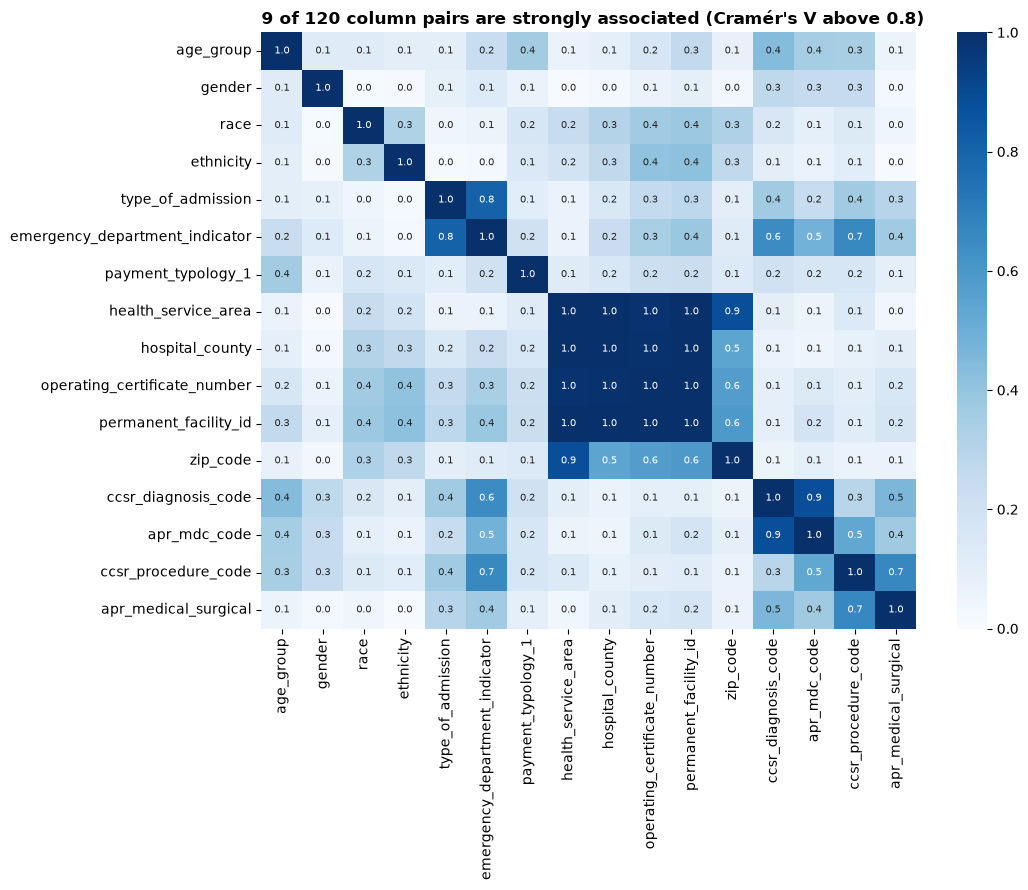

In [21]:
cols = ["age_group", "gender", "race", "ethnicity",
        "type_of_admission", "emergency_department_indicator", "payment_typology_1",
        "health_service_area", "hospital_county", "operating_certificate_number", "permanent_facility_id", "zip_code",
        "ccsr_diagnosis_code", "apr_mdc_code", "ccsr_procedure_code", "apr_medical_surgical"]

s = df_clean[cols]

def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))


v = pd.DataFrame(1.0, index=cols, columns=cols)
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        v.loc[a, b] = v.loc[b, a] = cramers_v(s[a], s[b])

upper = v.values[np.triu_indices(len(cols), k=1)]

plt.figure(figsize=(11, 9))
sns.heatmap(v, annot=True, fmt=".1f", annot_kws={"size": 7}, cmap="Blues", vmin=0, vmax=1)
plt.title(f"{(upper > 0.8).sum()} of {len(upper)} column pairs are strongly associated "
          f"(Cramér's V above 0.8)", loc="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "cramers_v_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

**Observations**
- **Location columns are nested.** Health service area, county, operating certificate and facility ID are all about 1.0 with each other. The facility id is the granular level and determines the other three.
- **Diagnosis determines MDC.** `ccsr_diagnosis_code` and `apr_mdc_code` have V = 0.9. The MDC is assigned from the principal diagnosis (HCUP, p. 57). It is not 1.0 because some cases get their MDC through other rules (transplant, tracheostomy and similar).
- **Medical/surgical is related to the procedure, but not determined by it.** `apr_medical_surgical` and `ccsr_procedure_code` have V = 0.7. In the APR-DRG logic a stay is surgical when an operating-room procedure was performed (HCUP, p. 57), which the procedure category alone does not fully show.
- **Admission type and ED indicator overlap** (V = 0.8) but are not copies (section 3.8).
- **Zip code** is 0.9 with health service area but only about 0.6 with the facility, so it adds geographic detail the facility does not.

**Decision:** drop `hospital_county`, `health_service_area`, `operating_certificate_number` (nested under `permanent_facility_id`) and `apr_mdc_code` (a coarser version of `ccsr_diagnosis_code`, V = 0.9).

**Keep** `apr_medical_surgical`, `type_of_admission`, `emergency_department_indicator` and `zip_code`.

In [22]:
redundant_cols = ["hospital_county", "health_service_area", "operating_certificate_number","apr_mdc_code"]
df_final = df_clean.drop(columns=redundant_cols)

print("shape:", df_final.shape)
print(df_final.columns.tolist())

OUT_PATH = Path("../data/processed/sparcs_2024_final.parquet")
OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
df_final.to_parquet(OUT_PATH)
print("saved:", OUT_PATH)

shape: (1993483, 15)
['permanent_facility_id', 'age_group', 'zip_code', 'gender', 'race', 'ethnicity', 'type_of_admission', 'ccsr_diagnosis_code', 'apr_medical_surgical', 'payment_typology_1', 'emergency_department_indicator', 'ccsr_procedure_code', 'payment_typology_2', 'payment_typology_3', 'los']
saved: ../data/processed/sparcs_2024_final.parquet


## 4. EDA charts

All charts use `df_final`: the main cohort (newborns excluded) after cleaning, with the 14 features and the target `los`.

### 4.1 Length of stay distribution

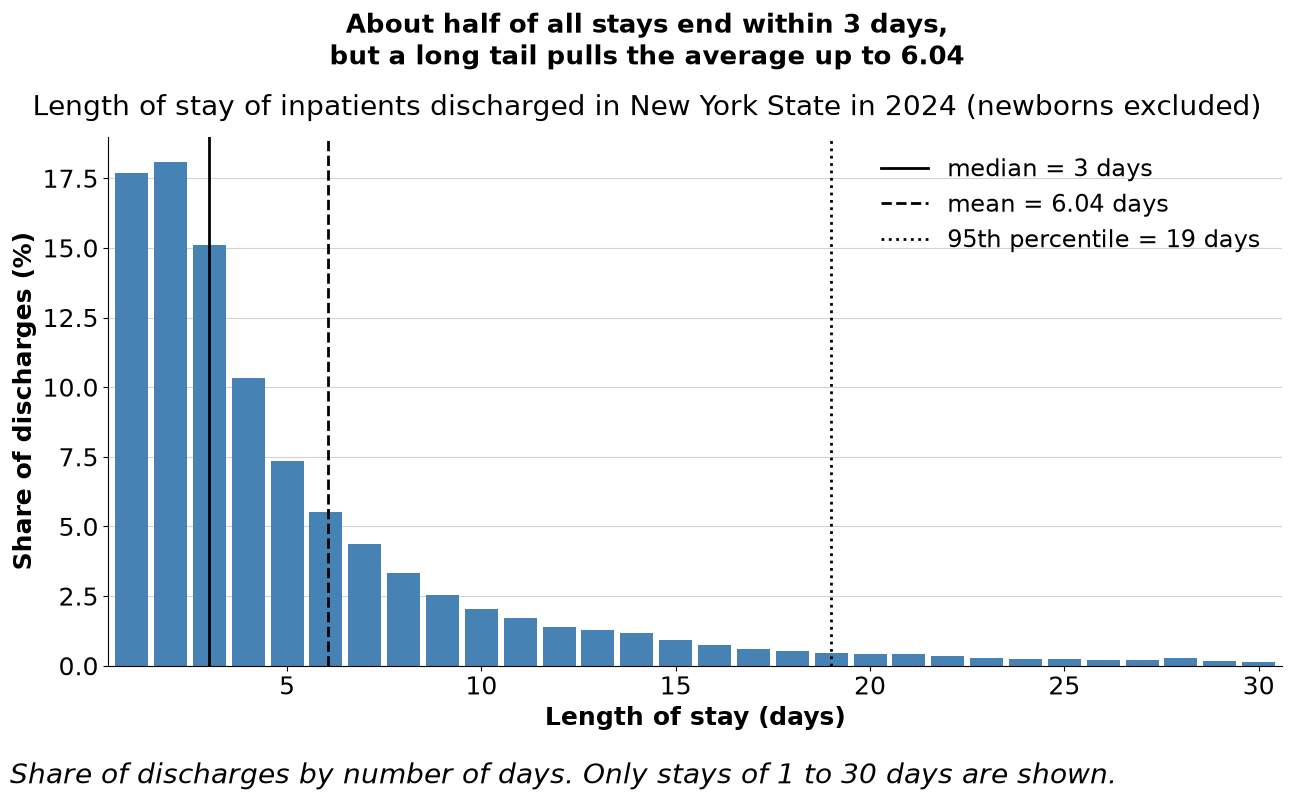

In [55]:
los = df_final["los"]
median, mean, p95 = los.median(), los.mean(), los.quantile(0.95)

pct = los.value_counts(normalize=True).sort_index() * 100     # % of discharges at each day count
body = pct.loc[1:30]

fig, ax = plt.subplots(figsize=(13, 8))
ax.bar(body.index, body.values, color="steelblue", width=0.85)

# three reference lines, told apart by line style and named in the legend
ax.axvline(median, color="black", lw=2, ls="-",  label=f"median = {median:.0f} days")
ax.axvline(mean,   color="black", lw=2, ls="--", label=f"mean = {mean:.2f} days")
ax.axvline(p95,    color="black", lw=2, ls=":",  label=f"95th percentile = {p95:.0f} days")
ax.legend(loc="upper right", frameon=False, fontsize=17)

ax.set_xlim(0.4, 30.6)
ax.set_xlabel("Length of stay (days)", fontsize=18, fontweight="bold")
ax.set_ylabel("Share of discharges (%)", fontsize=18, fontweight="bold")
ax.grid(axis="y", color="lightgray")
ax.set_axisbelow(True)
ax.tick_params(colors="black", labelsize= 18)
ax.spines[["top", "right"]].set_visible(False)

fig.text(0.5, 0.98, f"About half of all stays end within {median:.0f} days,\n"
                    f"but a long tail pulls the average up to {mean:.2f}",
         fontsize=19, fontweight="bold", ha="center", va="top")
fig.text(0.5, 0.875, "Length of stay of inpatients discharged in New York State in 2024 (newborns excluded)",
         fontsize=20, color="black", ha="center", va="top")
fig.text(0.01, 0.005, "Share of discharges by number of days. Only stays of 1 to 30 days are shown.",
         fontsize=20, style="italic", color="black", ha="left", va="bottom")
plt.tight_layout(rect=[0, 0.06, 1, 0.84])
plt.savefig(FIG_DIR / "los_distribution_1_to_30_days.png", dpi=150, bbox_inches="tight")
plt.show()

- Stays are short: about half of all discharges end within 3 days (17.7% at 1 day, 18.1% at 2 days, 15.1% at 3 days).
- The distribution is strongly right-skewed. The mean (6.04 days) is about twice the median (3 days), and the 95th percentile is 19 days.

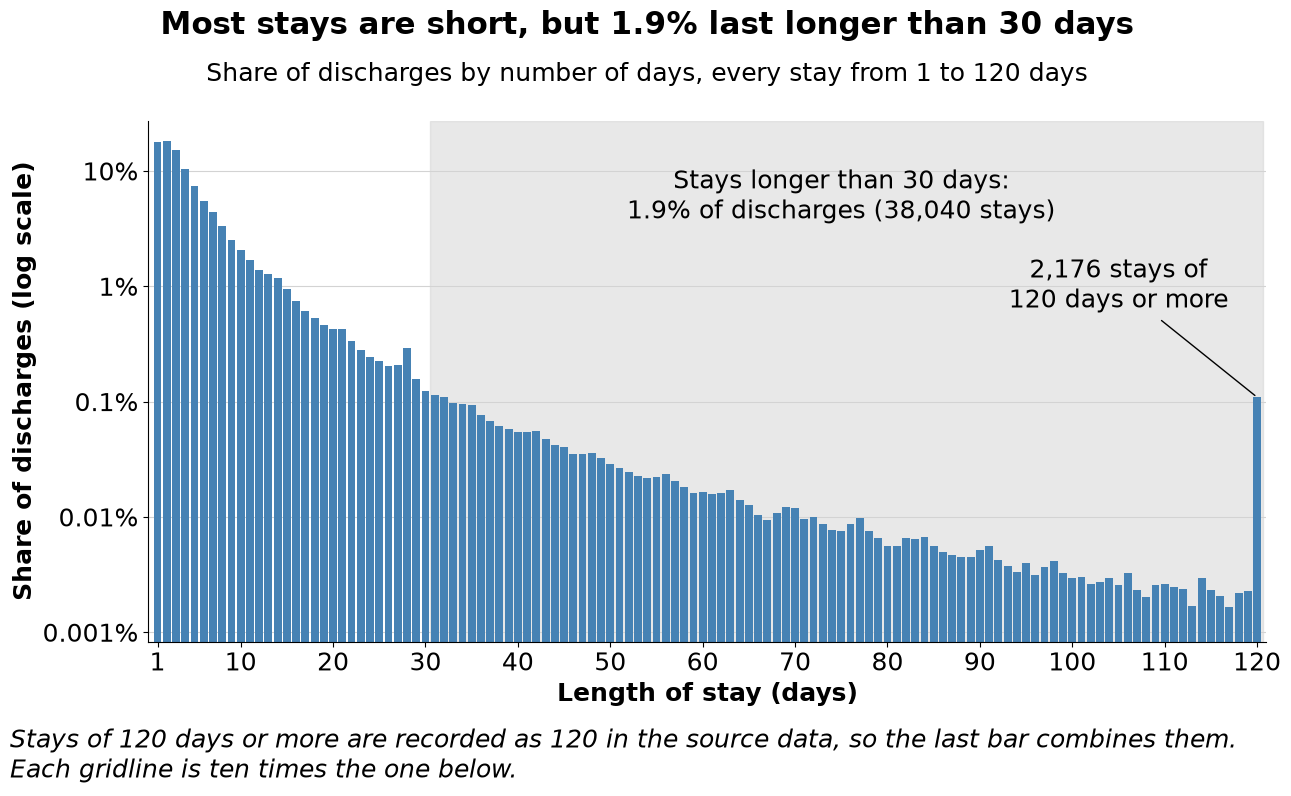

In [185]:
share_long = (los > 30).mean() * 100
n_long = (los > 30).sum()
n_cap = (los == los.max()).sum()

# share of discharges at every day count from 1 to 120 (days with no stays are left empty)
pct = los.value_counts(normalize=True).reindex(range(1, 121)) * 100
pct = pct.where(pct > 0)

fig, ax = plt.subplots(figsize=(13, 8))
ax.axvspan(30.5, 120.6, color="lightgray", alpha=0.5)          # stays longer than 30 days
ax.bar(pct.index, pct.values, color="steelblue", width=0.85)

ax.set_yscale("log")                                           # the tail is invisible on a linear scale
ax.set_ylim(pct.min() / 2, pct.max() * 1.5)
ax.minorticks_off()
ax.set_yticks([0.001, 0.01, 0.1, 1, 10])
ax.set_yticklabels(["0.001%", "0.01%", "0.1%", "1%", "10%"])
ax.set_xlim(0, 121)
ax.set_xticks([1] + list(range(10, 121, 10)))

ax.text(75, pct.max() * 0.6, f"Stays longer than 30 days:\n{share_long:.1f}% of discharges ({n_long:,} stays)",
        ha="center", va="top", fontsize=18, color="black")
ax.annotate(f"{n_cap:,} stays of\n120 days or more", xy=(120, pct[120]), xytext=(105, pct[120] * 6),
            ha="center", fontsize=18, color="black", arrowprops=dict(arrowstyle="-", color="black"))

ax.set_xlabel("Length of stay (days)", fontsize=18, fontweight="bold")
ax.set_ylabel("Share of discharges (log scale)", fontsize=18, fontweight="bold")
ax.grid(axis="y", color="lightgray")
ax.set_axisbelow(True)
ax.tick_params(colors="black", labelsize=18)
ax.spines[["top", "right"]].set_visible(False)

fig.text(0.5, 0.98, f"Most stays are short, but {share_long:.1f}% last longer than 30 days",
         fontsize=22, fontweight="bold", ha="center", va="top")
fig.text(0.5, 0.915, f"Share of discharges by number of days, every stay from 1 to {los.max()} days",
         fontsize=18, color="black", ha="center", va="top")
fig.text(0.01, 0.01, "Stays of 120 days or more are recorded as 120 in the source data, so the last bar combines them.\n"
                     "Each gridline is ten times the one below.",
         fontsize=18, style="italic", color="black", ha="left", va="bottom")
plt.tight_layout(rect=[0, 0.09, 1, 0.86])
plt.savefig(FIG_DIR / "los_distribution_all_stays.png", dpi=150, bbox_inches="tight")
plt.show()

- 1.9% of discharges are stays longer than 30 days, so about 98% last 30 days or fewer.
- Stays of 120 days or more are capped at 120 in the source, so the target is right-censored there.

### 4.2 Category shares

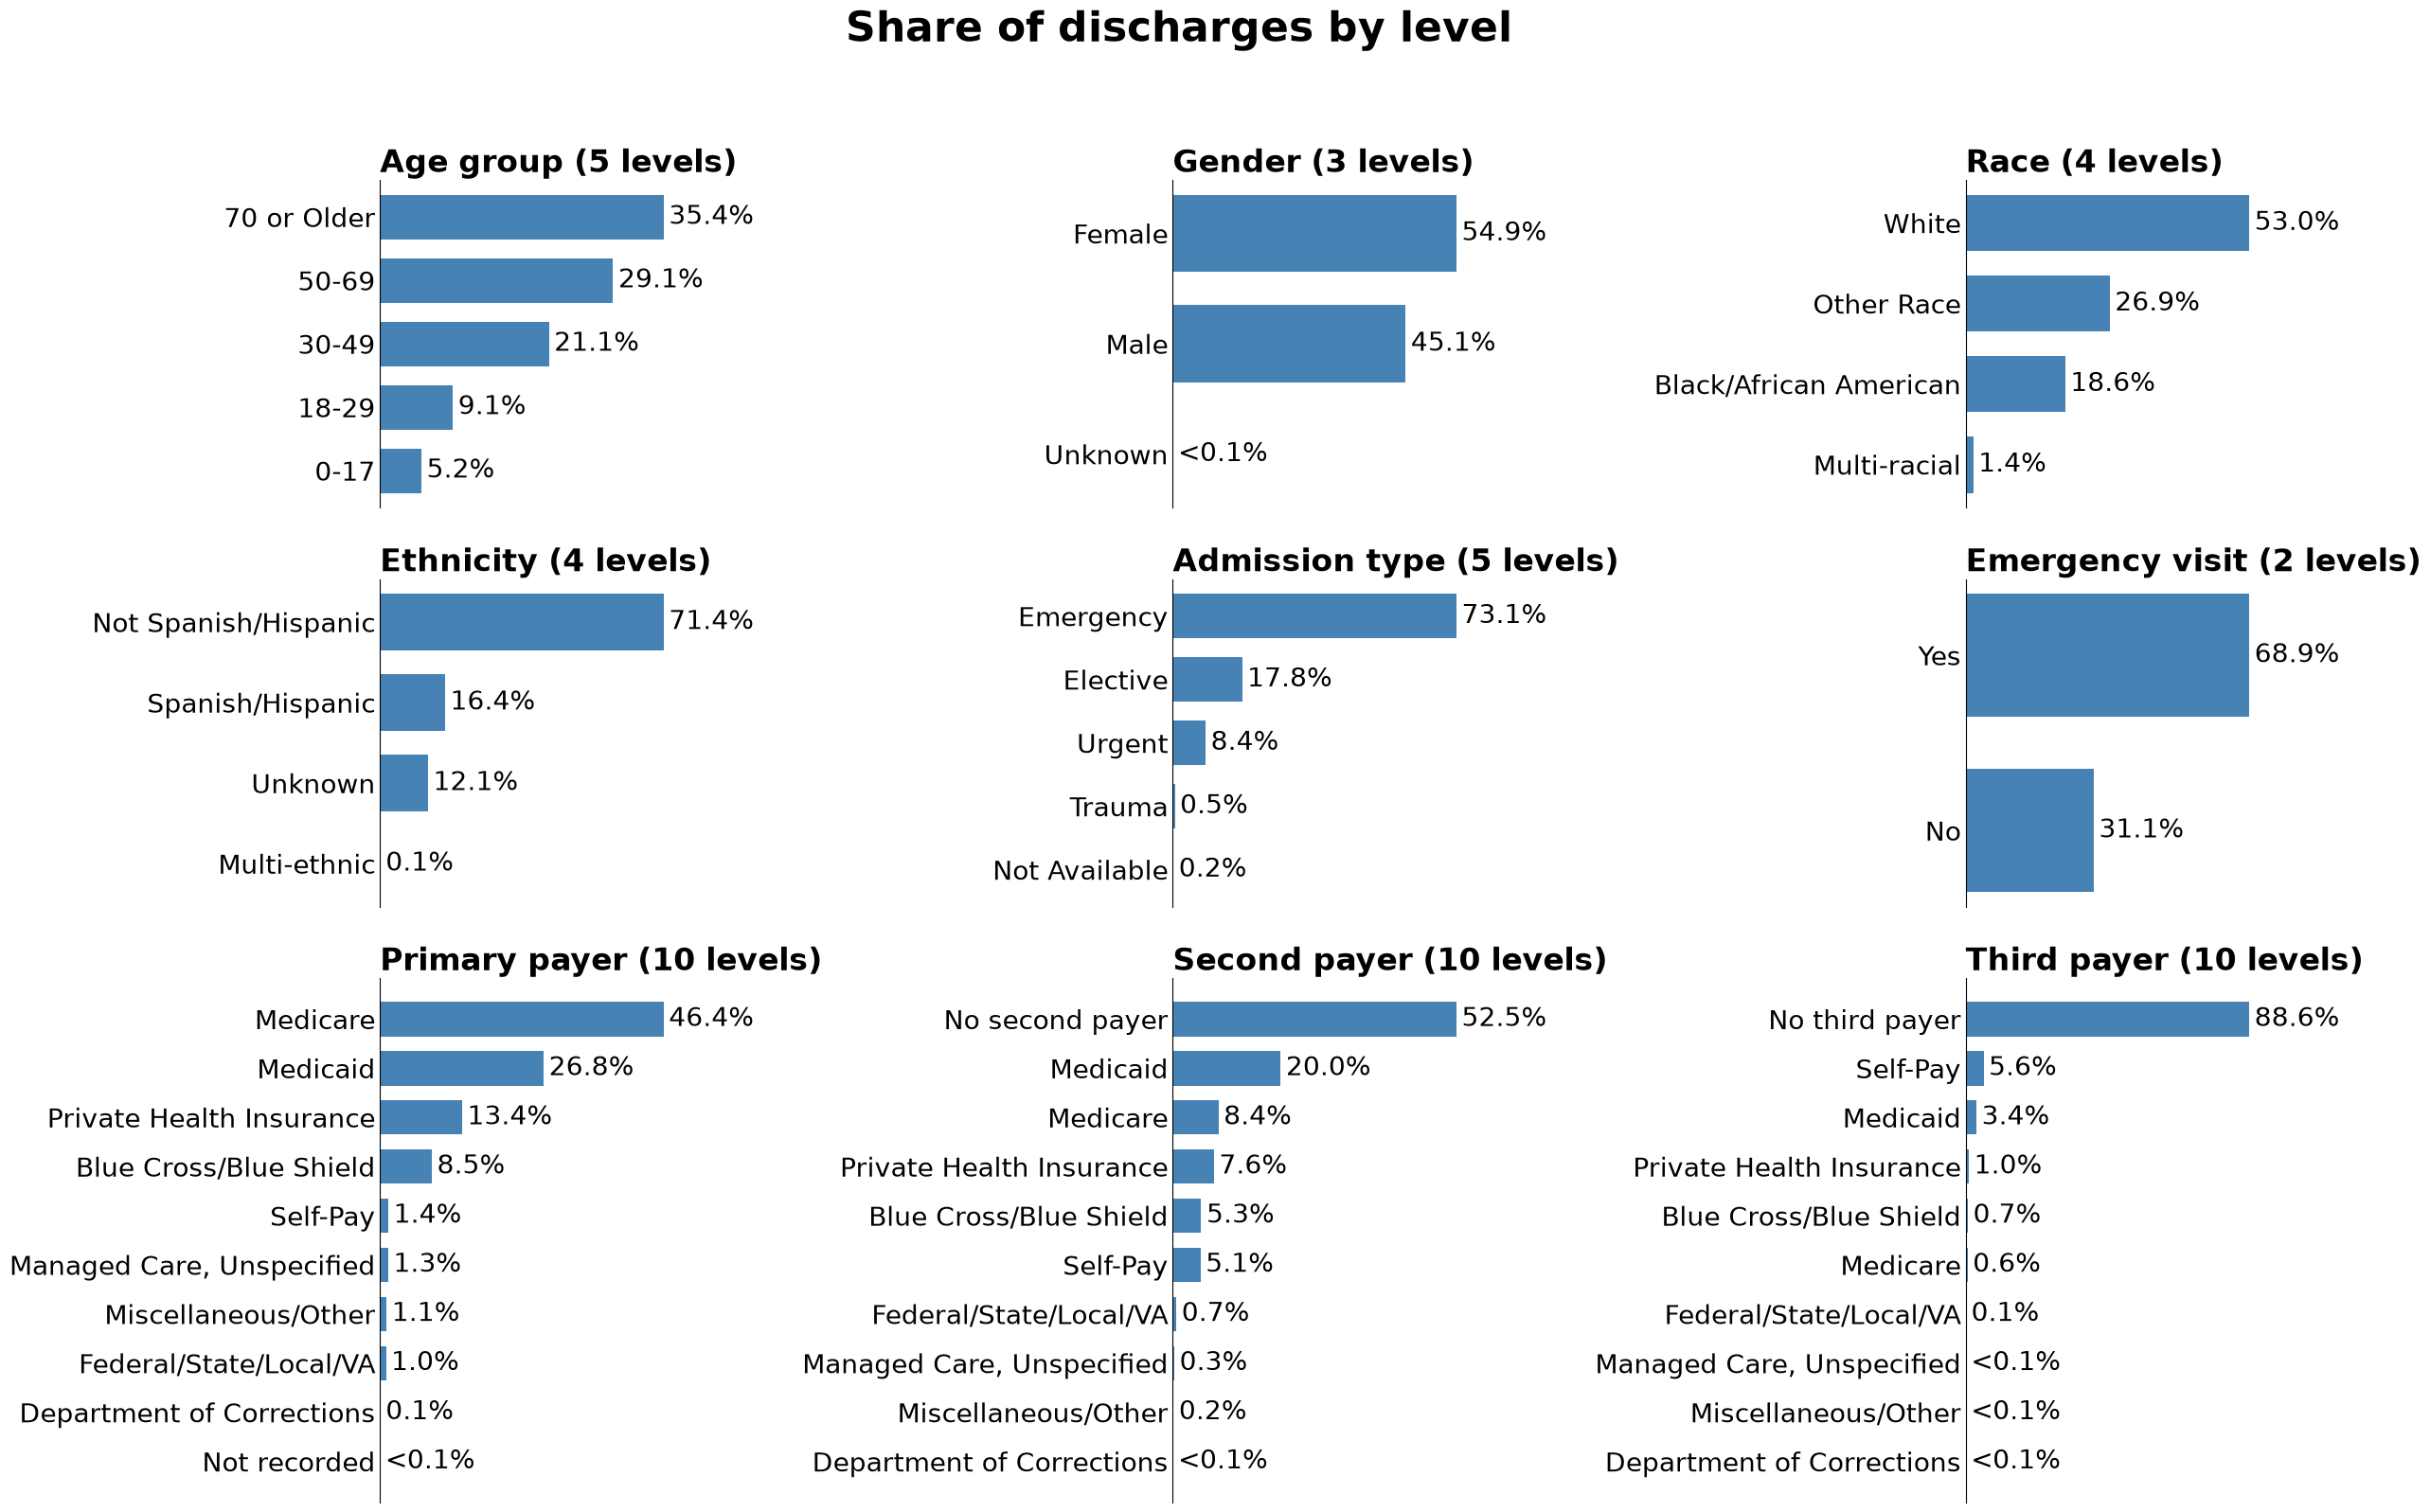

In [182]:
cols = ["age_group", "gender", "race", "ethnicity", "type_of_admission", "emergency_department_indicator",
        "payment_typology_1", "payment_typology_2", "payment_typology_3"]
titles = {"age_group": "Age group", "gender": "Gender", "race": "Race", "ethnicity": "Ethnicity",
          "type_of_admission": "Admission type", "emergency_department_indicator": "Emergency visit",
          "payment_typology_1": "Primary payer", "payment_typology_2": "Second payer", "payment_typology_3": "Third payer"}

level_names = {"F": "Female", "M": "Male", "U": "Unknown", "Y": "Yes", "N": "No",
               "Not Span/Hispanic": "Not Spanish/Hispanic"}

fig, axes = plt.subplots(3, 3, figsize=(25, 16), gridspec_kw={"height_ratios": [1, 1, 1.6]})
for ax, col in zip(axes.flat, cols):
    share = df_final[col].value_counts(normalize=True).mul(100).sort_values()
    ax.barh([level_names.get(s, s) for s in share.index.astype(str)], share.values, color="steelblue", height=0.7)
    ax.bar_label(ax.containers[0], labels=[f"{v:.1f}%" if v >= 0.05 else "<0.1%" for v in share.values], fontsize=20, padding=4)
    ax.set_title(f"{titles.get(col, col)} ({len(share)} levels)", loc="left", fontsize=24, fontweight="bold")
    ax.set_xlim(0, share.max() * 1.35)
    ax.set_xticks([])
    ax.tick_params(axis="y", labelsize=20, length=0, colors="black")
    ax.spines[["top", "right", "bottom"]].set_visible(False)

fig.suptitle("Share of discharges by level", x=0.5, y=0.995, ha="center", fontsize=32, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.95], h_pad=3, w_pad=3)
plt.savefig(FIG_DIR / "category_shares.png", dpi=150, bbox_inches="tight")
plt.show()

- The population is older and mostly emergency admissions: 35.5% are 70 or older and 29.1% are 50-69, while 0-17 is 5.2%. Emergency is 73.1% of admissions and 68.9% pass through the ED.
- Medicare (46.4%) and Medicaid (26.8%) dominate the primary payer. Just over half have no second payer (52.5%), and 88.6% have no third payer.

### 4.3 Diagnosis and length of stay

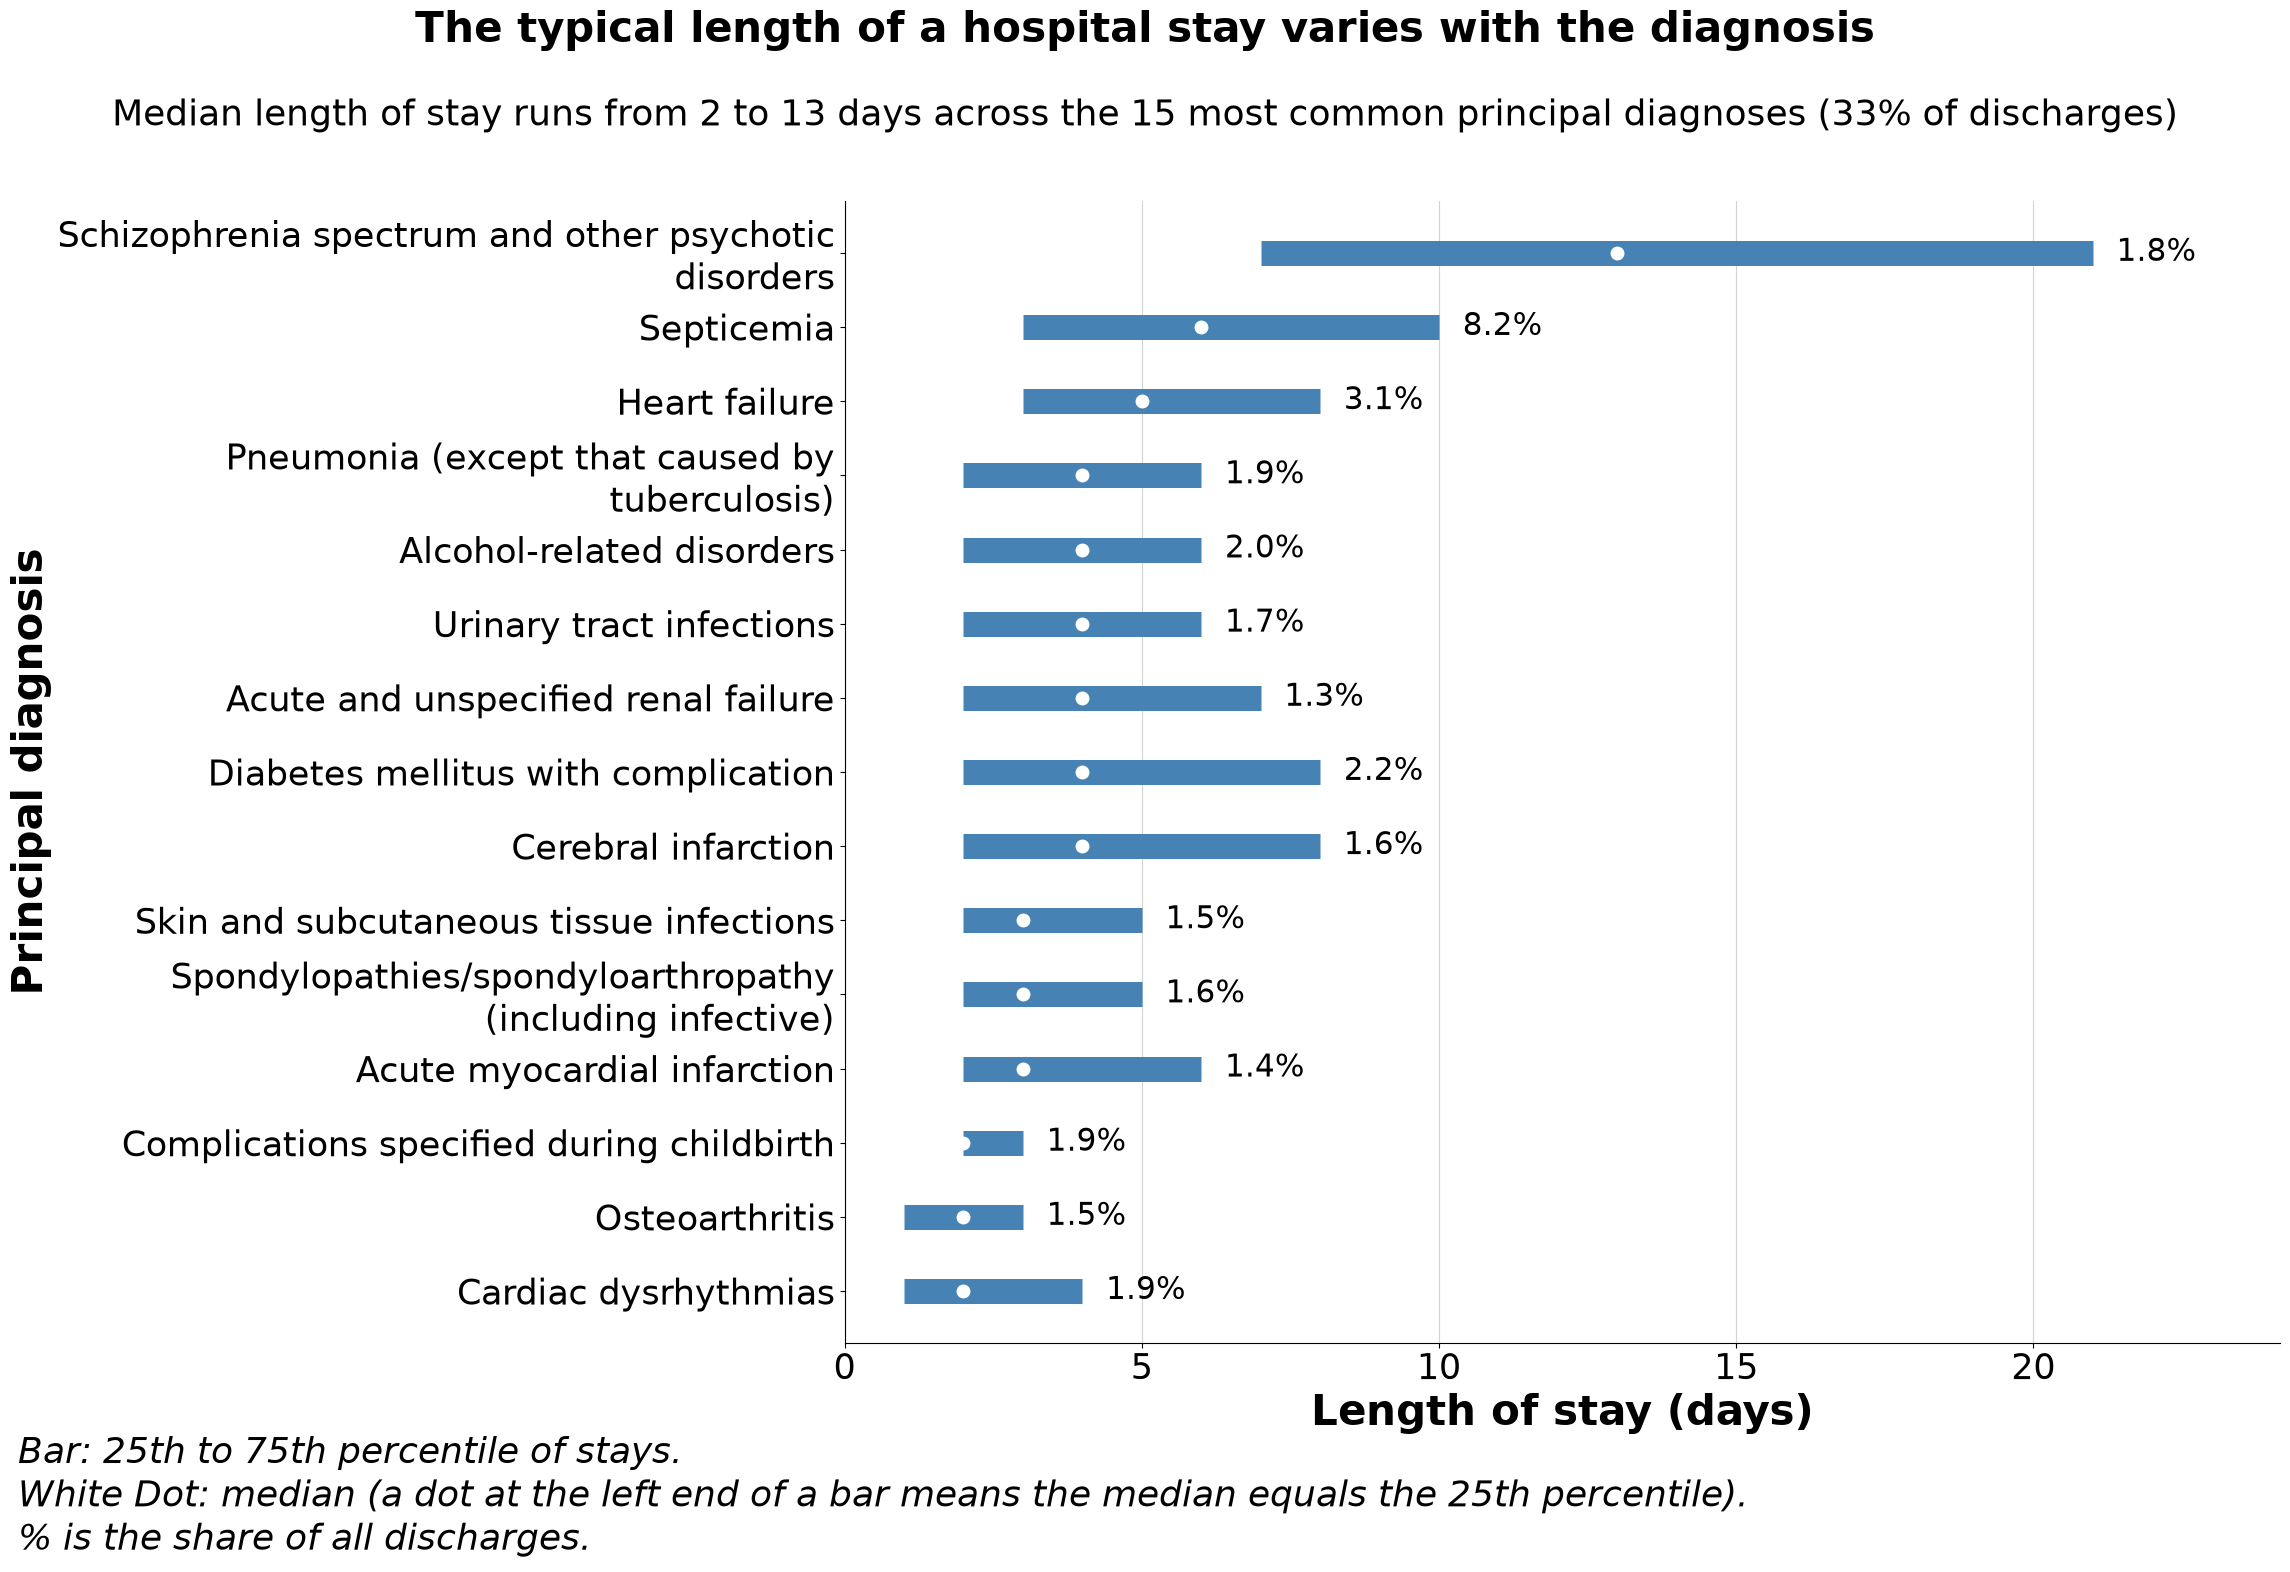

In [146]:
names = df_raw.drop_duplicates("ccsr_diagnosis_code").set_index("ccsr_diagnosis_code")["ccsr_diagnosis_description"]

# the 15 most common diagnoses
top_codes = df_final["ccsr_diagnosis_code"].value_counts().head(15).index
top = df_final[df_final["ccsr_diagnosis_code"].isin(top_codes)]
top_share = len(top) / len(df_final)

# median and middle half of the stay for each, shortest median first
stats = top.groupby("ccsr_diagnosis_code")["los"].quantile([0.25, 0.5, 0.75]).unstack().sort_values(0.5)
counts = top["ccsr_diagnosis_code"].value_counts()

fig, ax = plt.subplots(figsize=(23, 16))
y = range(len(stats))
ax.hlines(y, stats[0.25], stats[0.75], color="steelblue", lw=18)    # 25th to 75th percentile
ax.plot(stats[0.5], y, "o", color="white", ms=9)                    # median

for i, code in enumerate(stats.index):                              # share of all discharges, next to each bar
    share = counts[code] / len(df_final) * 100
    ax.text(stats.loc[code, 0.75] + 0.4, i, f"{share:.1f}%", va="center", fontsize=22, color="black")

ax.set_yticks(list(y))
ax.set_yticklabels([textwrap.fill(names[c].capitalize(), 45) for c in stats.index], fontsize=18)
ax.set_xlabel("Length of stay (days)", fontsize=30, fontweight="bold")
ax.set_ylabel("Principal diagnosis", fontsize=30, fontweight="bold")
ax.set_xlim(0, stats[0.75].max() * 1.15)
ax.grid(axis="x", color="lightgray")
ax.set_axisbelow(True)
ax.tick_params(colors="black", labelsize=25)
ax.spines[["top", "right"]].set_visible(False)

fig.text(0.5, 0.98, "The typical length of a hospital stay varies with the diagnosis",
         fontsize=30, fontweight="bold", ha="center", va="top")
fig.text(0.5, 0.925, f"Median length of stay runs from {stats[0.5].min():.0f} to {stats[0.5].max():.0f} days across the "
                     f"15 most common principal diagnoses ({top_share:.0%} of discharges)",
         fontsize=26, color="black", ha="center", va="top")
fig.text(0.01, 0.01, "Bar: 25th to 75th percentile of stays. \nWhite Dot: median (a dot at the left end of a bar means "
                     "the median equals the 25th percentile). \n% is the share of all discharges.",
         fontsize=26, style="italic", color="black", ha="left", va="bottom")
plt.tight_layout(rect=[0, 0.08, 1, 0.87])
plt.savefig(FIG_DIR / "diagnosis_vs_los.png", dpi=150, bbox_inches="tight")
plt.show()

- The diagnosis separates the typical stay strongly: among the 15 most common diagnoses the median runs from about 2 days to about 13 days.
- It also changes the spread: the middle half of schizophrenia stays runs from about 7 to 21 days, while for osteoarthritis and cardiac dysrhythmias it is only about 1 to 4 days.

### 4.4 Procedure and length of stay

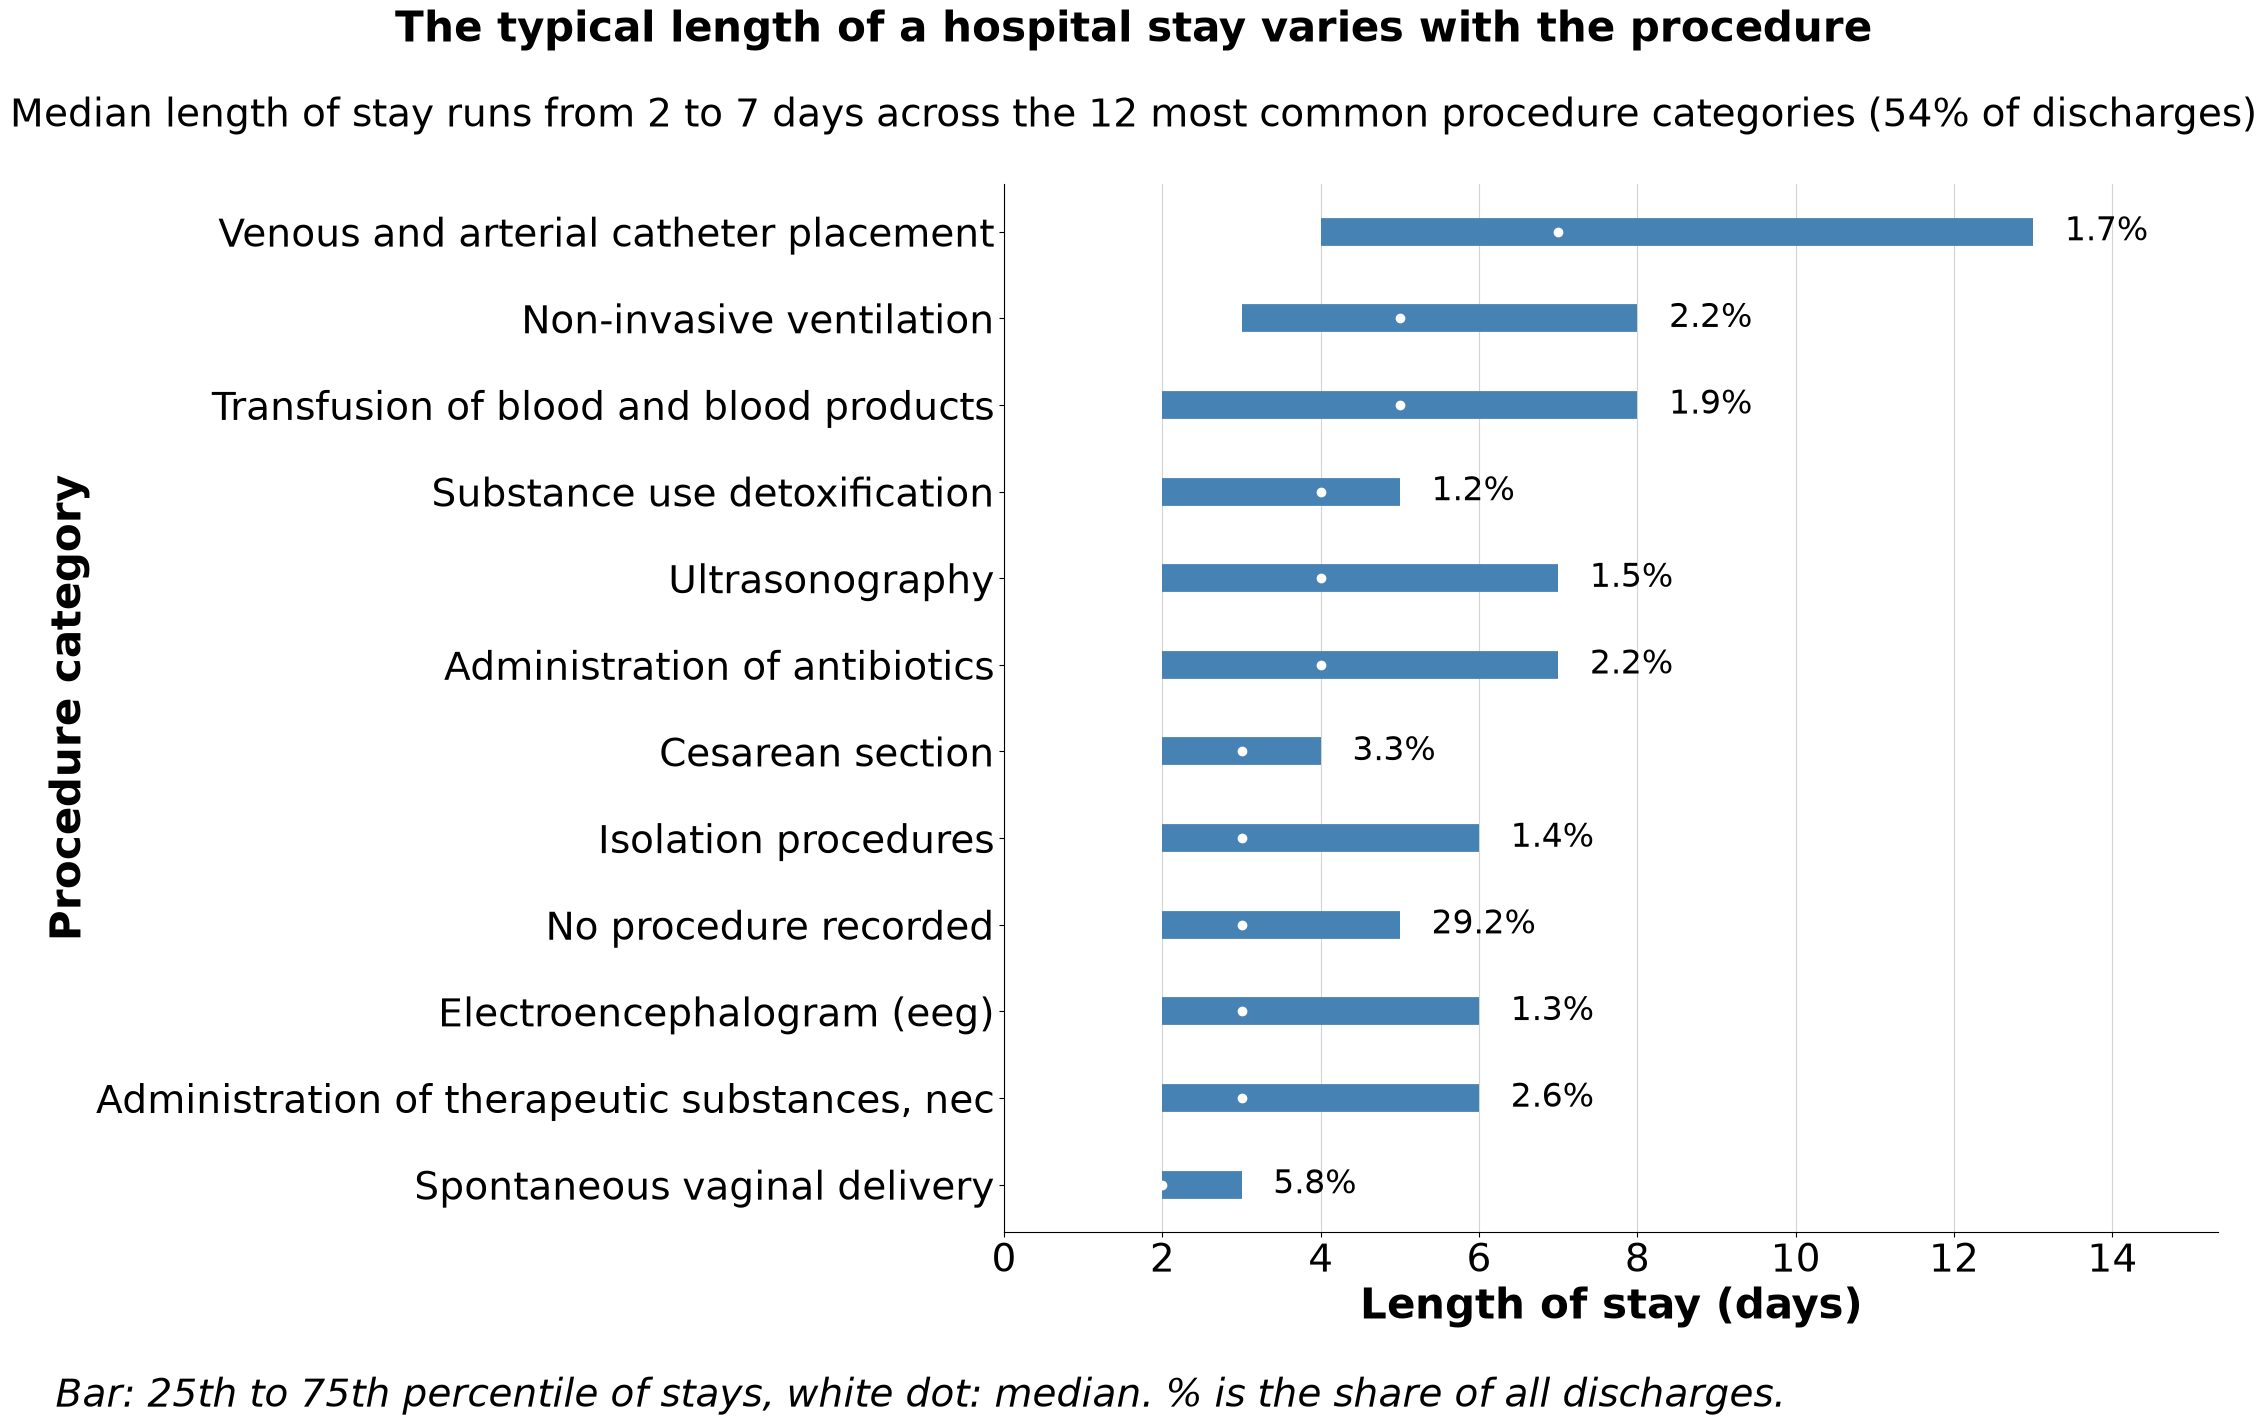

In [150]:
pnames = df_raw.drop_duplicates("ccsr_procedure_code").set_index("ccsr_procedure_code")["ccsr_procedure_description"]

# the 12 most common procedure categories, including "No procedure recorded"
top_codes = df_final["ccsr_procedure_code"].value_counts().head(12).index
top = df_final[df_final["ccsr_procedure_code"].isin(top_codes)]
top_share = len(top) / len(df_final)

stats = top.groupby("ccsr_procedure_code")["los"].quantile([0.25, 0.5, 0.75]).unstack().sort_values(0.5)
share = top["ccsr_procedure_code"].value_counts() / len(df_final) * 100

fig, ax = plt.subplots(figsize=(22, 14.5))
y = range(len(stats))
ax.hlines(y, stats[0.25], stats[0.75], color="steelblue", lw=20)
ax.plot(stats[0.5], y, "o", color="white", ms=6)
for i, code in enumerate(stats.index):
    ax.text(stats.loc[code, 0.75] + 0.4, i, f"{share[code]:.1f}%", va="center", fontsize=24, color="black")

ax.set_yticks(list(y))
ax.set_yticklabels([textwrap.fill(pnames.get(c, c).capitalize(), 55) for c in stats.index], fontsize=10)
ax.set_xlim(0, stats[0.75].max() * 1.18)
ax.set_xlabel("Length of stay (days)", fontsize=30, fontweight="bold")
ax.set_ylabel("Procedure category", fontsize=30, fontweight="bold")
ax.grid(axis="x", color="lightgray")
ax.set_axisbelow(True)
ax.tick_params(colors="black", labelsize= 28)
ax.spines[["top", "right"]].set_visible(False)

fig.text(0.5, 0.98, "The typical length of a hospital stay varies with the procedure",
         fontsize=30, fontweight="bold", ha="center", va="top")
fig.text(0.5, 0.92, f"Median length of stay runs from {stats[0.5].min():.0f} to {stats[0.5].max():.0f} days across the "
                    f"12 most common procedure categories ({top_share:.0%} of discharges)",
         fontsize=28, color="black", ha="center", va="top")
fig.text(0.01, 0.01, "Bar: 25th to 75th percentile of stays, white dot: median. % is the share of all discharges.",
         fontsize=28, style="italic", color="black", ha="left", va="bottom")
plt.tight_layout(rect=[0, 0.06, 1, 0.87])
plt.savefig(FIG_DIR / "procedure_vs_los.png", dpi=150, bbox_inches="tight")
plt.show()

- Among the 12 most common procedure categories the typical stay runs from about 2 days (spontaneous vaginal delivery) to about 7 days (venous and arterial catheter placement, middle half 4 to 13 days).
- Delivery and cesarean section are the shortest (2 to 3 days). Catheter placement, non-invasive ventilation and blood transfusion are the longest (5 to 7 days).

### 4.5 Length of stay by age group, primary payer, race and emergency department use

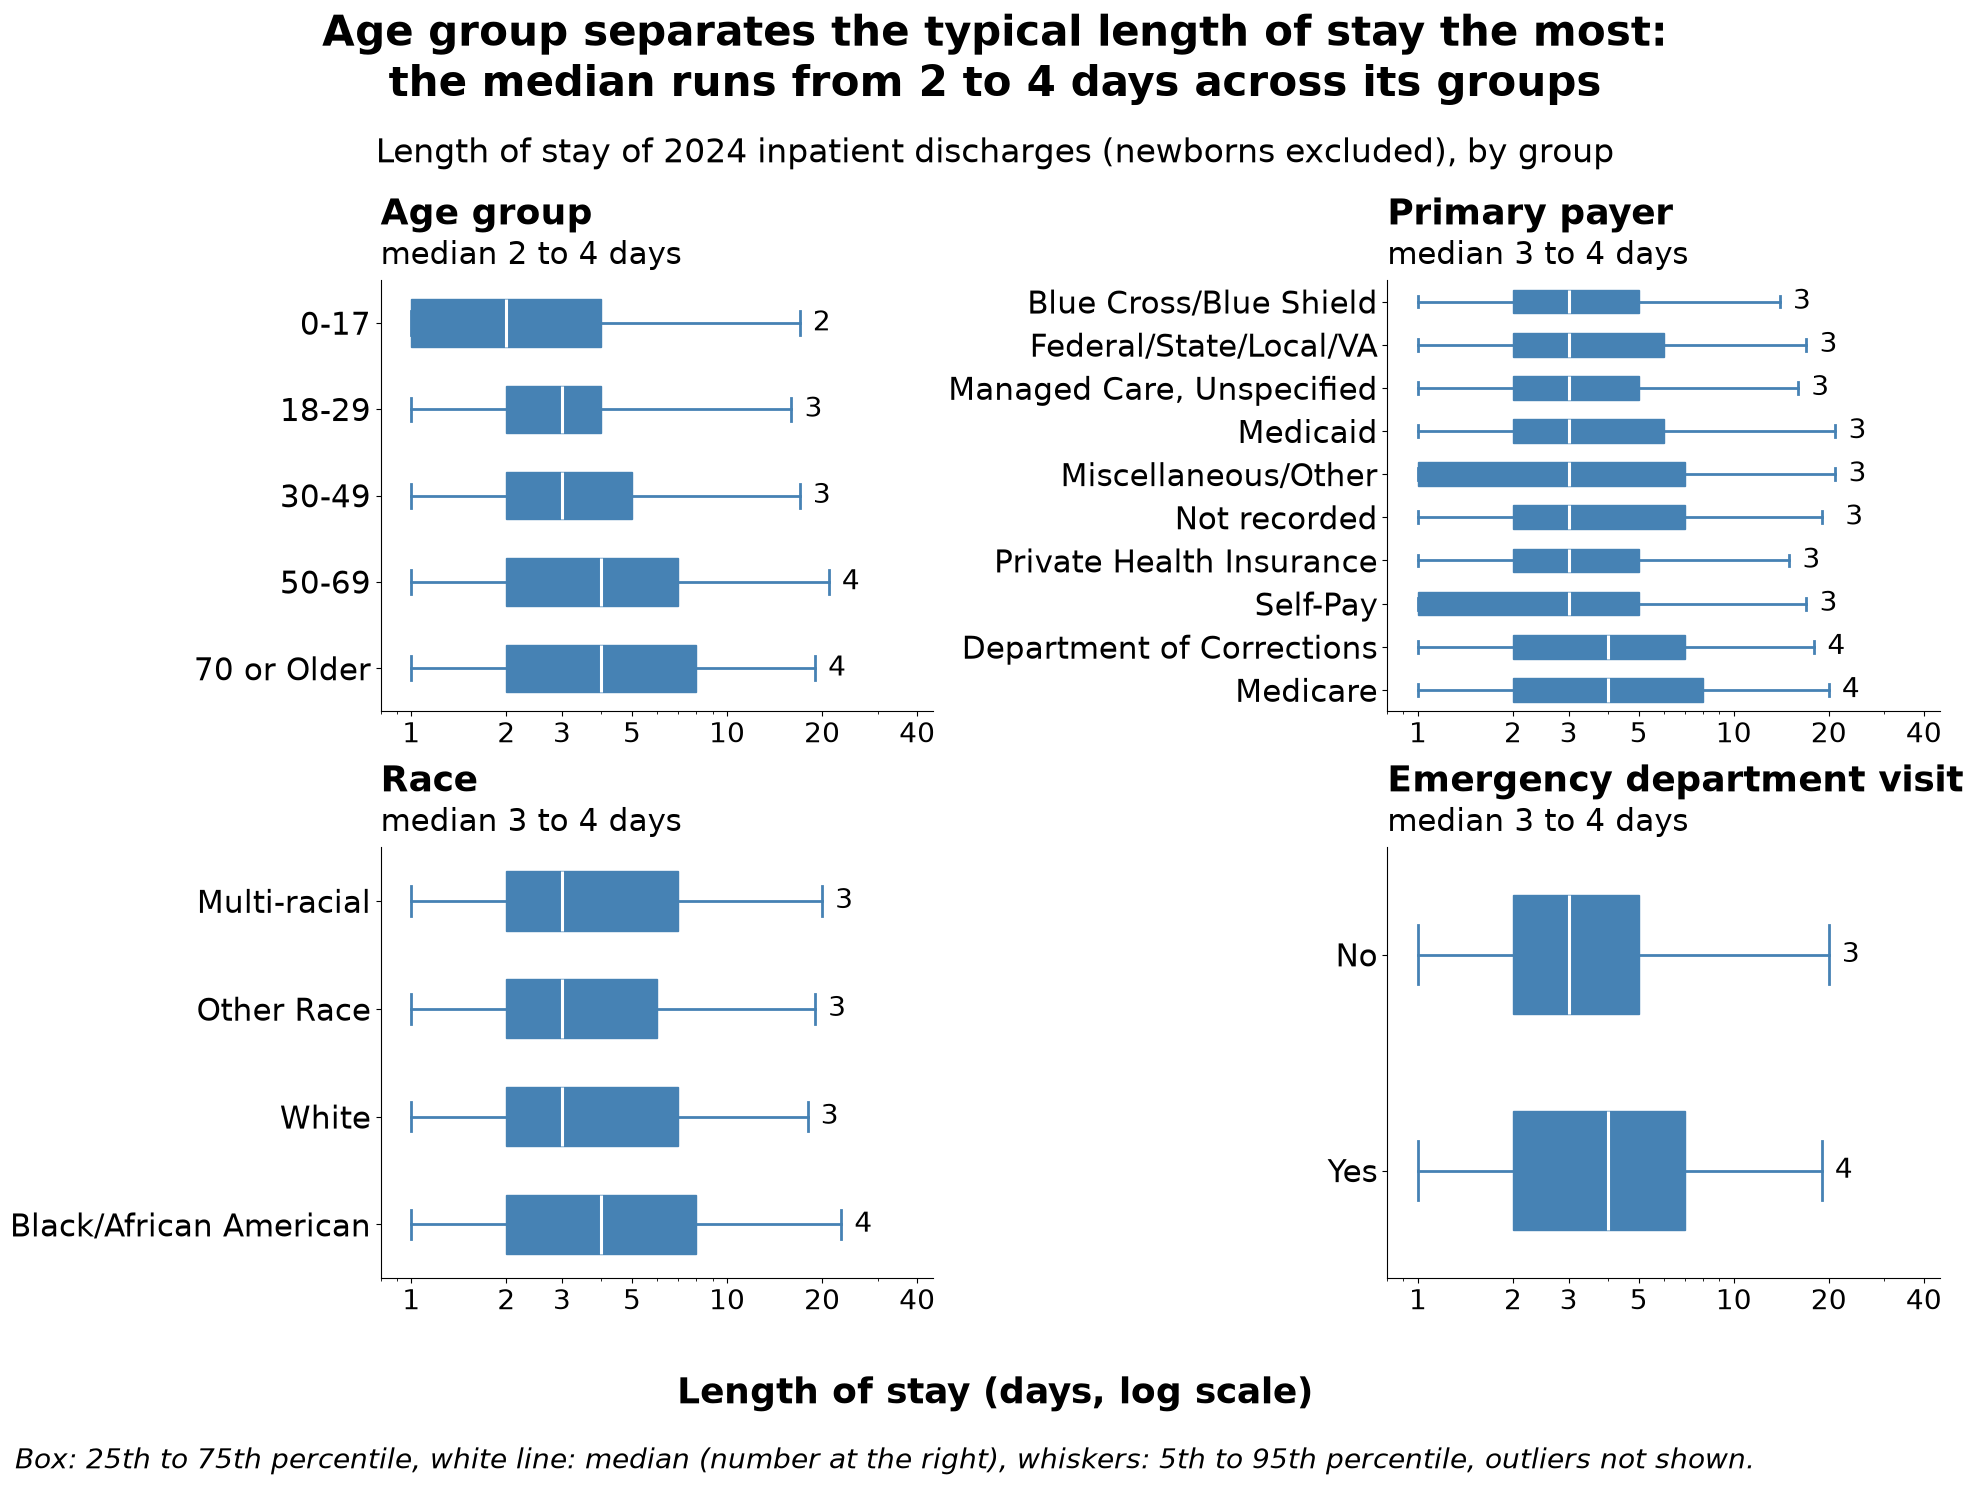

In [177]:
panels = [
    ("age_group", "Age group"),
    ("payment_typology_1", "Primary payer"),
    ("race", "Race"),
    ("emergency_department_indicator", "Emergency department visit"),
]
age_order = ["0-17", "18-29", "30-49", "50-69", "70 or Older"]
median_range = {}
yes_no = {"N": "No", "Y": "Yes"}

fig, axes = plt.subplots(2, 2, figsize=(20, 15), sharex=True)

for ax, (col, label) in zip(axes.flat, panels):
    med = df_final.groupby(col)["los"].median().sort_values()
    median_range[label] = (med.min(), med.max())
    order = age_order if col == "age_group" else med.index
    groups = [df_final.loc[df_final[col] == g, "los"] for g in order]

    ax.boxplot(groups, orientation="horizontal", whis=(5, 95), showfliers=False, patch_artist=True, widths=0.55,
               medianprops=dict(color="white", linewidth=2.2),
               boxprops=dict(facecolor="steelblue", edgecolor="steelblue"),
               whiskerprops=dict(color="steelblue", linewidth=2), capprops=dict(color="steelblue", linewidth=2))
    ax.invert_yaxis()                                      # first group on top
    ax.set_xscale("log")                                   # LOS is heavily right-skewed
    ax.set_xticks([1, 2, 3, 5, 10, 20, 40])
    ax.set_xticklabels([1, 2, 3, 5, 10, 20, 40])
    ax.set_xlim(0.8, 45)
    ax.tick_params(labelbottom=True, labelsize=20)                       # show the x labels on the top row too
    ax.set_yticklabels([yes_no.get(g, g) for g in order], fontsize=22)

    for i, g in enumerate(groups, start=1):                # label each median directly
        ax.text(np.percentile(g, 95) * 1.1, i, f"{np.median(g):.0f}", ha="left", va="center", fontsize=20)

    ax.set_title(label, loc="left", fontsize=26, fontweight="bold", pad=40)
    ax.text(0, 1.02, f"median {med.min():.0f} to {med.max():.0f} days", transform=ax.transAxes,
            ha="left", va="bottom", fontsize=22)
    ax.spines[["top", "right"]].set_visible(False)

# headline names the characteristic whose groups differ most in median stay
widest = max(median_range, key=lambda k: median_range[k][1] - median_range[k][0])
lo, hi = median_range[widest]

fig.supxlabel("Length of stay (days, log scale)", y=0.05, fontsize=26, fontweight="bold")
fig.text(0.5, 0.985, f"{widest} separates the typical length of stay the most:\n"
                     f"the median runs from {lo:.0f} to {hi:.0f} days across its groups",
         fontsize=30, fontweight="bold", ha="center", va="top")
fig.text(0.5, 0.90, "Length of stay of 2024 inpatient discharges (newborns excluded), by group",
         fontsize=24, ha="center", va="top")
fig.text(0.01, 0.008, "Box: 25th to 75th percentile, white line: median (number at the right), whiskers: 5th to 95th percentile, outliers not shown.",
         fontsize=20, style="italic", ha="left", va="bottom")
plt.tight_layout(rect=[0, 0.07, 0.98, 0.87])
plt.savefig(FIG_DIR / "los_by_group.png", dpi=150, bbox_inches="tight")
plt.show()

- **Age group:** the median stay rises from 2 days for 0-17 to 4 days for 50-69 and 70 or older.
- **Primary payer:** the median is 3 days for most payers and 4 for Medicare and Department of Corrections.
- **Race:** the median is 3 days for most groups and 4 for Black/African American patients.
- **Emergency department visit:** the median is 3 days without an ED visit and 4 days with one.
- Every box spans a wide range, so no single characteristic separates long stays from short ones by itself.